In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

from astropy.table import vstack

In [2]:
BBC_P21_highz = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ.FITRES.gz")
print(BBC_P21_highz.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [3]:
BBC_P21_highz_corr_max = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MAX.FITRES.gz")
print(BBC_P21_highz_corr_max.colnames)

['VARNAMES:', 'CID', 'CIDint', 'IDSURVEY', 'TYPE', 'FIELD', 'CUTFLAG_SNANA', 'ERRFLAG_FIT', 'zHEL', 'zHELERR', 'zCMB', 'zCMBERR', 'zHD', 'zHDERR', 'VPEC', 'VPECERR', 'LENSDMU', 'LENSDMUERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'HOST_LOGSFR', 'HOST_LOGSFR_ERR', 'HOST_LOGsSFR', 'HOST_LOGsSFR_ERR', 'HOST_COLOR', 'HOST_COLOR_ERR', 'HOST_MAG_u', 'HOST_MAG_g', 'HOST_MAG_r', 'HOST_MAG_i', 'HOST_MAG_z', 'HOST_MAG_Y', 'PKMJDINI', 'SNRMAX1', 'SNRMAX2', 'SNRMAX3', 'SNRSUM', 'BANDLIST', 'PKMJD', 'PKMJDERR', 'x1', 'x1ERR', 'c', 'cERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'NDOF', 'FITCHI2', 'FITPROB', 'RADIUS_POP', 'SIM_GENTYPE', 'SIM_TEMPLATE_INDEX', 'SIM_LIBID', 'SIM_NGEN_LIBID', 'SIM_ZCMB', 'SIM_ZFLAG', 'SIM_VPEC', 'SIM_DLMAG', 'SIM_LENSDMU', 'SIM_PEAKMJD', 'SIM_WGT_POP', 'SIM_x1', 'SIM_c', 'SIM_alpha', 'SIM_beta', 'SIM_gammaDM', 'SIM_x0', 'SIM_mB', 'SIM_AV', 'SIM_RV', 'RA', 'DEC', 'TGAPMAX', 'TrestMIN', 'TrestMAX']


In [5]:
BBC_P21_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ.FITRES")

In [28]:
BBC_P21_lowz_corr_max = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MAX.FITRES")

In [6]:
P21_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_LSST_LOWZ.FITRES")

In [7]:
P21_highz = ascii.read("../sims/LSST/HIGHZ/FITOPT000_LSST_HIGHZ.FITRES")

In [44]:
BBC_P21 = vstack([BBC_P21_lowz,BBC_P21_highz])
BBC_P21_corr_max = vstack([BBC_P21_lowz_corr_max,BBC_P21_highz_corr_max])

In [42]:
P21 = vstack([P21_lowz,P21_highz])

In [45]:
print(np.unique(P21['FIELD']))

FIELD
-----
  DDF
  WFD


In [46]:
print(np.unique(BBC_P21_corr_max['FIELD']))

FIELD
-----
  DDF
  WFD


In [11]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [47]:
#### SIMS ####
print("******* LSST sims *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(BBC_P21[create_filt(BBC_P21)])}\t{np.min(BBC_P21['zHD'][create_filt(BBC_P21)]):.2f}\t{np.max(BBC_P21['zHD'][create_filt(BBC_P21)]):.2f}")
print()
print("Deep")
print(f"{len(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')])}\t{np.min(BBC_P21['zHD'][create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')]):.2f}\t{np.max(BBC_P21['zHD'][create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')]):.2f}")

******* LSST sims *******
N	z_min	z_max

Total
5541224	0.01	1.29

Deep
143486	0.01	1.29


In [48]:
#### DATA ####
print("******* LSST data *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(P21[create_filt(P21)])}\t{np.min(P21['zHD'][create_filt(P21)]):.2f}\t{np.max(P21['zHD'][create_filt(P21)]):.2f}")
print()
print("Deep")
print(f"{len(P21[create_filt(P21)&(P21['FIELD']=='DDF')])}\t{np.min(P21['zHD'][create_filt(P21)&(P21['FIELD']=='DDF')]):.2f}\t{np.max(P21['zHD'][create_filt(P21)&(P21['FIELD']=='DDF')]):.2f}")

******* LSST data *******
N	z_min	z_max

Total
138500	0.01	1.29

Deep
3646	0.05	1.29


In [14]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

In [39]:
def find_drop(x,y):
    small_drop = True
    i=0
    while (small_drop == True):
        if (y[i]-y[i+1]) > 0.012:
            z_drop = (x[i]+x[i+1])/2
            small_drop = False
        i+=1
        
    return z_drop

In [16]:
def plot_drop(nodust,dust):
    bin_edges = np.linspace(np.min(dust['zHD']),np.max(dust['zHD']),31)
    bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

    filt = create_filt(nodust)
    corr_filt = create_filt(dust)
    
    bin_count_nodust, _, _ = binned_statistic(nodust['zHD'][filt],nodust['zHD'][filt],statistic='count',bins=bin_edges)
    bin_count_dust, _, _ = binned_statistic(dust['zHD'][corr_filt],dust['zHD'][corr_filt],statistic='count',bins=bin_edges)
    
    bin_edges_nodust, c_bin_means_nodust, c_bin_std_nodust = bin_vals(nodust['zHD'][filt],nodust['c'][filt])
    bin_edges_dust, c_bin_means_dust, c_bin_std_dust = bin_vals(dust['zHD'][corr_filt],dust['c'][corr_filt])
    
    z_drop = find_drop(bin_zs,bin_count_dust/bin_count_nodust)
    
    #PLOTTING
    fig = plt.figure(figsize=(5,6))
    ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.43])

    plt.scatter(bin_zs,
                bin_count_dust/bin_count_nodust,label='highz',zorder=2)
    legend1 = plt.legend(loc='lower right')

    plt.axvline(x=z_drop,
                color='C0',ls='--',alpha=0.4)

    ax = plt.gca()
    orange_dotted = mlines.Line2D([], [], color="C0", linestyle="--", label=f"$z={z_drop:.2f}$",alpha=0.6)
    legend2 = ax.legend(handles=[orange_dotted],loc='lower left')

    ax.add_artist(legend1)

    plt.title("LSST Simulation",fontsize=16)
    plt.ylabel("$N_\mathrm{i.g. dust}/N_\mathrm{nominal}$",fontsize=14)

    ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.43])
    plt.scatter(bin_zs,c_bin_means_nodust-c_bin_means_dust,zorder=2)
    plt.xlabel("Binned $z$",fontsize=14)
    plt.ylabel("Binned $c_\mathrm{nominal}-c_\mathrm{i.g. dust}$",fontsize=14)

    plt.axvline(x=z_drop,
                color='C0',ls='--',alpha=0.4)

#     plt.show()
    
    return z_drop

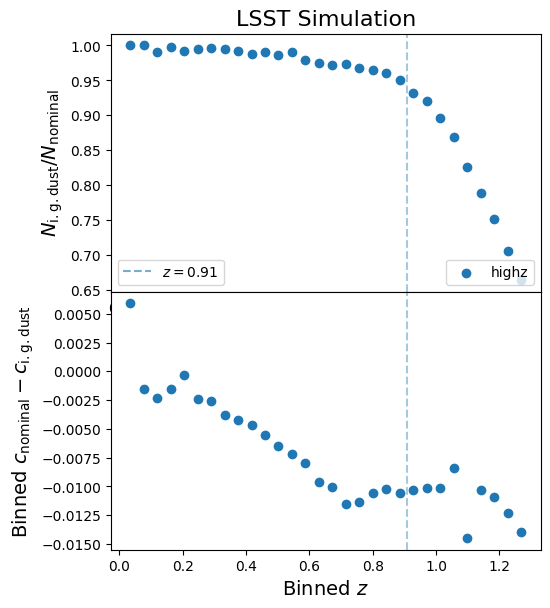

In [73]:
#DEEP
z_drop_deep = plot_drop(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')],BBC_P21_corr_max[create_filt(BBC_P21_corr_max)&(BBC_P21_corr_max['FIELD']=='DDF')])
# plt.savefig("pdfs/LSST_sim_compare.pdf",bbox_inches='tight')
plt.show()

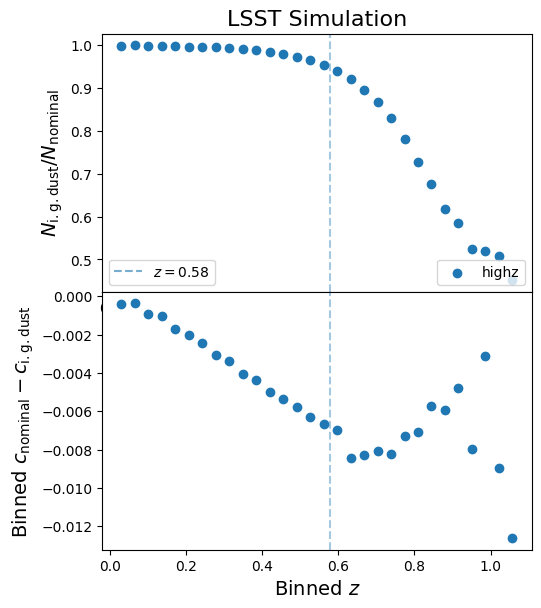

In [52]:
#SHALLOW
z_drop_shallow = plot_drop(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='WFD')],BBC_P21_corr_max[create_filt(BBC_P21_corr_max)&(BBC_P21_corr_max['FIELD']=='WFD')])
plt.show()

In [53]:
""" MEANS splitting by field shallow/deep """
def calc_c_vs_z(data,sims_list,zmin=0.0,zmax=0.1,delta=0.1,N=15,offset=0):
    sim = sims_list[0]
    
    zmin = 0.1
    zmax = 0.2
    delta = 0.1 #was at 0.2 and zmax at 0.3

    z_means = []
    shallow_data_c_means = []
    shallow_data_c_stds = []

    shallow_sim_c_means = []
    shallow_sim_c_stds = []
    
    deep_data_c_means = []
    deep_data_c_stds = []

    deep_sim_c_means = []
    deep_sim_c_stds = []

    
    total_N_data = 0

    for i in tqdm(range(N)): #was at 5
        shallow_data_z_filt = (data['zHD'] <= z_drop_shallow) & (data['FIELD'] == 'WFD') & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        bins = np.arange(-0.3,0.35,0.05)

        #data  
        if (z_drop_shallow - zmin) > 0.04:
            shallow_data_c_means.append(np.mean(data['c'][shallow_data_z_filt]))
            shallow_data_c_stds.append(np.std(data['c'][shallow_data_z_filt])/np.sqrt(len(data['c'][shallow_data_z_filt])))

        deep_data_z_filt = (data['zHD'] <= z_drop_deep) & (data['FIELD'] == 'DDF') & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        if (z_drop_deep - zmin) > 0.04:
            deep_data_c_means.append(np.mean(data['c'][deep_data_z_filt]))
            deep_data_c_stds.append(np.std(data['c'][deep_data_z_filt])/np.sqrt(len(data['c'][deep_data_z_filt])))

        total_N_data+=len(data[shallow_data_z_filt])
        total_N_data+=len(data[deep_data_z_filt])

        
        #sims
        shallow_sim_z_filt = (sim['zHD'] <= z_drop_shallow) & (sim['FIELD'] == 'WFD') & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_shallow - zmin) > 0.04:
            shallow_sim_c_means.append(np.mean(sim['c'][shallow_sim_z_filt])+offset)
            shallow_sim_c_stds.append(np.std(sim['c'][shallow_sim_z_filt])/np.sqrt(len(sim['c'][shallow_sim_z_filt])))

        deep_sim_z_filt = (sim['zHD'] <= z_drop_deep) & (sim['FIELD'] == 'DDF') & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_deep - zmin) > 0.04:
            deep_sim_c_means.append(np.mean(sim['c'][deep_sim_z_filt])+offset)
            deep_sim_c_stds.append(np.std(sim['c'][deep_sim_z_filt])/np.sqrt(len(sim['c'][deep_sim_z_filt])))

        z_means.append((zmin+zmax)/2)                           


        zmin+=delta
        zmax+=delta
    print(total_N_data)
    
    
    z_means = np.array(z_means)
    shallow_data_c_means = np.array(shallow_data_c_means)
    shallow_data_c_stds = np.array(shallow_data_c_stds)
    shallow_sim_c_means = np.array(shallow_sim_c_means)
    shallow_sim_c_stds = np.array(shallow_sim_c_stds)
    
    deep_data_c_means = np.array(deep_data_c_means)
    deep_data_c_stds = np.array(deep_data_c_stds)
    deep_sim_c_means = np.array(deep_sim_c_means)
    deep_sim_c_stds = np.array(deep_sim_c_stds)
    
    return (z_means,shallow_data_c_means,shallow_data_c_stds,shallow_sim_c_means,shallow_sim_c_stds,deep_data_c_means,deep_data_c_stds,deep_sim_c_means,deep_sim_c_stds)

In [54]:
def plot_c_vs_z(z,c,cerr=[],label='',sim=True,color='C0'):
    """ plot one at a time (don't say plt.show()) """
    #sims
    if sim == True:
        plt.plot(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.8,color=color,capsize=2,lw=2)
    #data
    else:
        plt.scatter(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.4,color=color)
        
    
        
    plt.xlabel("$z$",fontsize=16)
    plt.ylabel("mean $c$",fontsize=16)
#     plt.xlim(0.0,1.1)
#     plt.ylim(-0.12,0.07)
    plt.legend(loc='upper right',fontsize=16)

In [55]:
def chi2(data,sim,data_err):
    return np.sum((np.array(data)-np.array(sim))**2/np.array(data_err)**2)

In [56]:
mz,sdc,sdc_s,ssc,ssc_s,ddc,ddc_s,dsc,dsc_s = calc_c_vs_z(P21,[BBC_P21],zmin=0.1,zmax=0.2)
_,_,_,ssc2,ssc_s2,_,_,dsc2,dsc_s2 = calc_c_vs_z(P21,[BBC_P21],zmin=0.1,zmax=0.2)
_,_,_,ssc3,ssc_s3,_,_,dsc3,dsc_s3 = calc_c_vs_z(P21,[BBC_P21_corr_max],zmin=0.1,zmax=0.2)

100%|███████████████████████████████████████████| 15/15 [00:03<00:00,  4.98it/s]


110139


100%|███████████████████████████████████████████| 15/15 [00:01<00:00,  9.75it/s]


110139


100%|███████████████████████████████████████████| 15/15 [00:01<00:00,  9.60it/s]

110139


In [57]:
#Fit for an offset between Data and Sim

def weighted_mean_difference(A, B, sigma_A, sigma_B):
    """
    Compute the weighted mean difference between two datasets A and B,
    taking into account their uncertainties sigma_A and sigma_B.

    Parameters:
    A (array-like): First set of values.
    B (array-like): Second set of values.
    sigma_A (array-like): Uncertainties associated with A.
    sigma_B (array-like): Uncertainties associated with B.

    Returns:
    tuple: (weighted mean difference, uncertainty of the weighted mean)
    """
    # Compute differences and propagated uncertainties
    D = np.array(A) - np.array(B)
    sigma_D = np.sqrt(np.array(sigma_A)**2 + np.array(sigma_B)**2)

    # Compute weighted mean difference
    weights = 1 / sigma_D**2
    D_mean = np.sum(D * weights) / np.sum(weights)

    # Compute uncertainty of the weighted mean
    sigma_D_mean = np.sqrt(1 / np.sum(weights))

    return D_mean, sigma_D_mean

In [58]:
wmd2 = weighted_mean_difference(dsc2,ddc,dsc_s2,ddc_s)[0]
wmd3 = weighted_mean_difference(dsc3,ddc,dsc_s3,ddc_s)[0]
print(wmd2)
print(wmd3)

swmd2 = weighted_mean_difference(ssc2,sdc,ssc_s2,sdc_s)[0]
swmd3 = weighted_mean_difference(ssc3,sdc,ssc_s3,sdc_s)[0]

0.0025199031214788773
0.010816755558949696


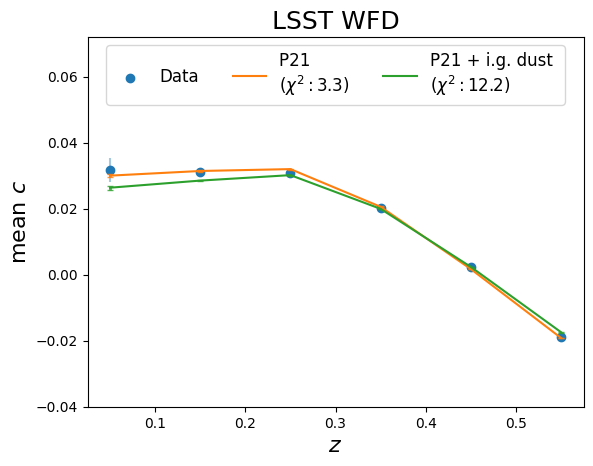

In [64]:
plt.title("LSST WFD",fontsize=18)
plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Data',sim=False)
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2)-swmd2,cerr=ssc_s2,label=f'P21 \n($\chi^2:{chi2(sdc,ssc2-swmd2,sdc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3)-swmd3,cerr=ssc_s3,label=f'P21 + i.g. dust \n($\chi^2:{chi2(sdc,ssc3-swmd3,sdc_s):.1f}$)',color='C2')
plt.legend(loc='upper center',fontsize=12,ncol=3)
# ax2.get_legend().remove()
plt.ylim(-0.04,0.072)
# plt.xlim(0,1)

# plt.savefig("pngs/LSST_shallow_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/LSST_shallow_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

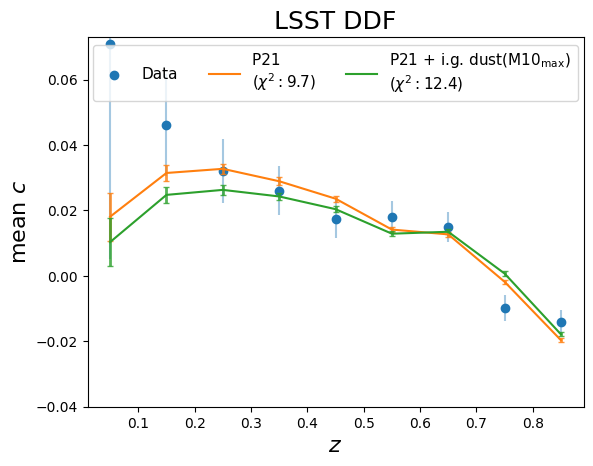

In [72]:
plt.title("LSST DDF",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'P21 \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'P21 + i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',color='C2')
plt.legend(loc='upper center',fontsize=11,ncol=3)
# ax2.get_legend().remove()
plt.ylim(-0.04,0.073)
# plt.xlim(0,1)

# plt.savefig("pngs/LSST_deep_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/LSST_deep_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

In [74]:
def plot_mu_dif(nodust,dust):
    mures = nodust['mB']+0.14*nodust['x1']-3.1*nodust['c']+19.35-nodust['SIM_DLMAG']
    corr_mures = dust['mB']+0.14*dust['x1']-3.1*dust['c']+19.35-dust['SIM_DLMAG']

    bin_edges1, mu_bin_means1, mu_bin_std1 = bin_vals(nodust['zHD'],mures)
    bin_edges2, mu_bin_means2, mu_bin_std2 = bin_vals(dust['zHD'],corr_mures)

    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2, mu_bin_means1,yerr=mu_bin_std1,
                 ls = 'none',marker='s', c='C3', label='nodust')
    plt.errorbar((bin_edges2[:-1] + bin_edges2[1:]) / 2, mu_bin_means2,yerr=mu_bin_std2,
                 ls = 'none',marker='s', c='C4', label='dust')

    plt.ylabel("$\mu_\mathrm{res}$ (mag)",fontsize=14)
    plt.xlabel("$z$",fontsize=14)
    plt.legend()

    plt.show()
    
    plt.figure(figsize=(6,4.5))
    plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,label="$\mu_\mathrm{i.g.~dust} - \mu_\mathrm{nom.}$",zorder=20)
    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,
                 yerr=np.sqrt(mu_bin_std1**2+mu_bin_std2**2),
                 ls = 'none',zorder=2)
    # plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,1*(bin_means3-bin_means1),label="BS20_corr - BS20")
    plt.xlabel("$z$",fontsize=14)
    plt.ylabel("$\Delta\mu$ (mag)",fontsize=14)
    plt.legend(fontsize=14,loc='upper left')
    plt.axhline(c='k',ls='--',zorder=1)
    plt.ylim(-0.005,0.03)
    # plt.savefig("pdfs/mu_from_igdust.pdf",bbox_inches='tight')
    # plt.savefig("pngs/mu_from_igdust.png",bbox_inches='tight')
#     plt.show()

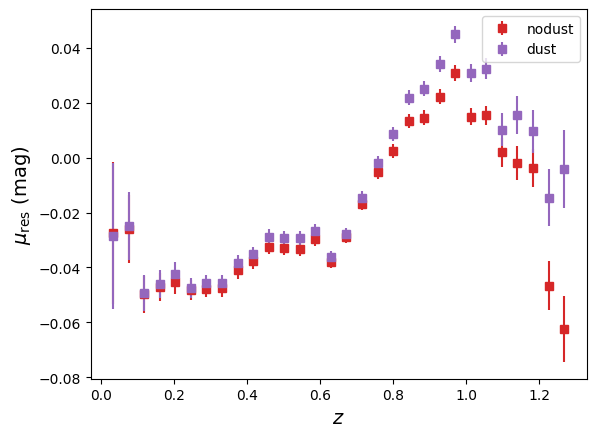

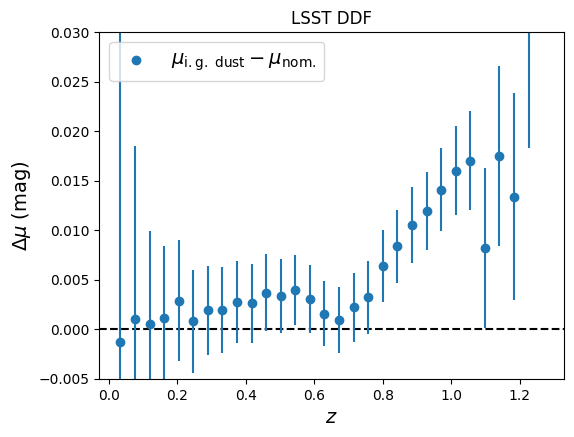

In [76]:
plot_mu_dif(BBC_P21[create_filt(BBC_P21)&(BBC_P21['FIELD']=='DDF')],BBC_P21_corr_max[create_filt(BBC_P21_corr_max)&(BBC_P21_corr_max['FIELD']=='DDF')])
plt.title("LSST DDF")
plt.savefig("pdfs/LSST_mu_dif.pdf",bbox_inches='tight')
plt.show()